In [19]:
import pandas as pd

In [20]:
df = pd.read_csv("workshops/3/bioresponse.csv")

In [21]:
df

,Activity,D1,D2,D3,D4,D5,D6,D7,D8,D9,...,D1767,D1768,D1769,D1770,D1771,D1772,D1773,D1774,D1775,D1776
0,1,0.000000,0.497009,0.10,0.0,0.132956,0.678031,0.273166,0.585445,0.743663,...,0,0,0,0,0,0,0,0,0,0
1,1,0.366667,0.606291,0.05,0.0,0.111209,0.803455,0.106105,0.411754,0.836582,...,1,1,1,1,0,1,0,0,1,0
2,1,0.033300,0.480124,0.00,0.0,0.209791,0.610350,0.356453,0.517720,0.679051,...,0,0,0,0,0,0,0,0,0,0
3,1,0.000000,0.538825,0.00,0.5,0.196344,0.724230,0.235606,0.288764,0.805110,...,0,0,0,0,0,0,0,0,0,0
4,0,0.100000,0.517794,0.00,0.0,0.494734,0.781422,0.154361,0.303809,0.812646,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3746,1,0.033300,0.506409,0.10,0.0,0.209887,0.633426,0.297659,0.376124,0.727093,...,0,0,0,0,0,0,0,0,0,0
3747,1,0.133333,0.651023,0.15,0.0,0.151154,0.766505,0.170876,0.404546,0.787935,...,0,0,1,0,1,0,1,0,0,0
3748,0,0.200000,0.520564,0.00,0.0,0.179949,0.768785,0.177341,0.471179,0.872241,...,0,0,0,0,0,0,0,0,0,0
3749,1,0.100000,0.765646,0.00,0.0,0.536954,0.634936,0.342713,0.447162,0.672689,...,0,0,0,0,0,0,0,0,0,0


In [22]:
df.isna().sum().sum()

np.int64(0)

In [23]:
df.describe()

,Activity,D1,D2,D3,D4,D5,D6,D7,D8,D9,...,D1767,D1768,D1769,D1770,D1771,D1772,D1773,D1774,D1775,D1776
count,3751.000000,3751.000000,3751.000000,3751.000000,3751.000000,3751.000000,3751.000000,3751.000000,3751.000000,3751.000000,...,3751.000000,3751.000000,3751.000000,3751.000000,3751.000000,3751.000000,3751.000000,3751.000000,3751.000000,3751.000000
mean,0.542255,0.076948,0.592436,0.068142,0.038990,0.212112,0.686653,0.274713,0.455133,0.749517,...,0.026926,0.014663,0.013863,0.021861,0.015196,0.016796,0.012263,0.011730,0.020261,0.011197
std,0.498278,0.079989,0.105860,0.078414,0.115885,0.102592,0.078702,0.090017,0.162731,0.071702,...,0.161889,0.120215,0.116938,0.146249,0.122348,0.128522,0.110074,0.107683,0.140911,0.105236
min,0.000000,0.000000,0.282128,0.000000,0.000000,0.002630,0.137873,0.006130,0.000000,0.275590,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.033300,0.517811,0.000000,0.000000,0.138118,0.625627,0.207374,0.378062,0.707339,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,1.000000,0.066700,0.585989,0.050000,0.000000,0.190926,0.674037,0.277845,0.499942,0.738961,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,1.000000,0.100000,0.668395,0.100000,0.000000,0.261726,0.740663,0.335816,0.569962,0.788177,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,1.000000,1.000000,0.964381,0.950000,1.000000,1.000000,0.994735,0.790831,0.989870,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [24]:
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    precision_score, recall_score, accuracy_score, f1_score, log_loss,
    precision_recall_curve, roc_curve, roc_auc_score, average_precision_score
)

In [25]:
X = df.drop('Activity', axis=1)
y = df['Activity']

In [26]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

In [27]:
models = {
    'Small Decision Tree': DecisionTreeClassifier(max_depth=3, random_state=42),
    'Deep Decision Tree': DecisionTreeClassifier(max_depth=15, random_state=42),
    'Random Forest (Small Trees)': RandomForestClassifier(n_estimators=100, max_depth=3, random_state=42, n_jobs=-1),
    'Random Forest (Deep Trees)': RandomForestClassifier(n_estimators=100, max_depth=15, random_state=42, n_jobs=-1)
}

In [28]:
for model in models.values():
    model.fit(X_train, y_train)

In [29]:
metrics_list = []

In [30]:
for name, model in models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    metrics_list.append({
        'Model': name,
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'Accuracy': accuracy_score(y_test, y_pred),
        'F1-score': f1_score(y_test, y_pred),
        'Log-loss': log_loss(y_test, y_prob)
    })

In [31]:
results_df = pd.DataFrame(metrics_list).set_index('Model')
results_df.round(4)

,Precision,Recall,Accuracy,F1-score,Log-loss
Model,,,,,
Small Decision Tree,0.7539,0.7525,0.7324,0.7532,0.7238
Deep Decision Tree,0.7464,0.8035,0.7452,0.7739,4.9846
Random Forest (Small Trees),0.7061,0.7741,0.7026,0.7385,0.6047
Random Forest (Deep Trees),0.7795,0.8055,0.7708,0.7923,0.4767


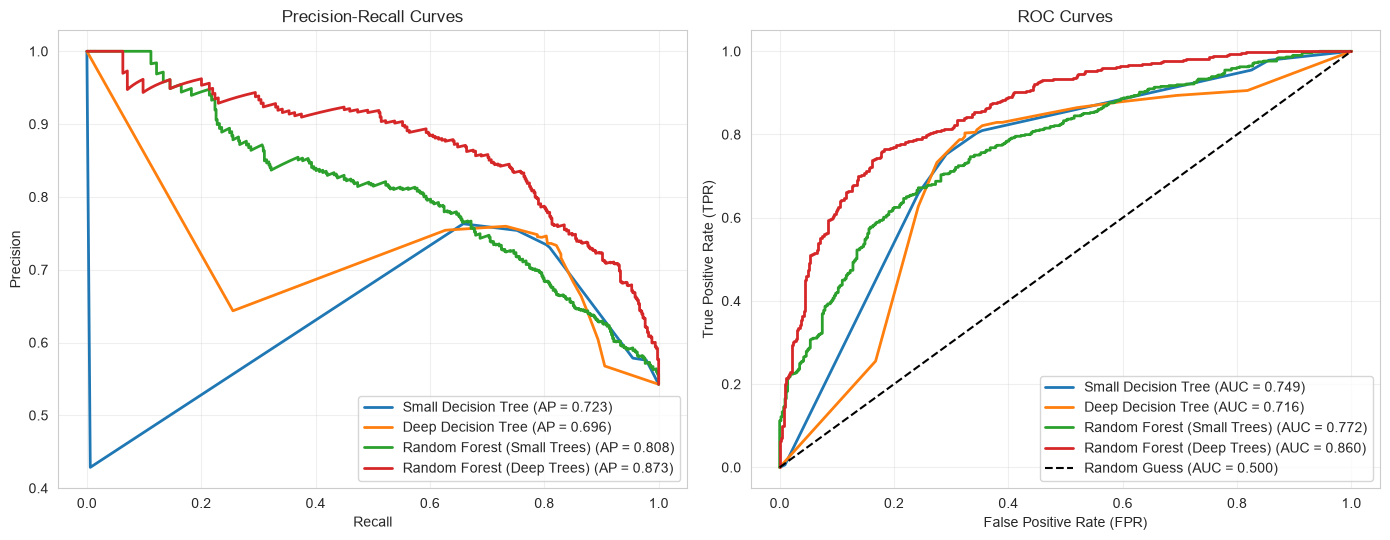

In [32]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

for name, model in models.items():
    y_prob = model.predict_proba(X_test)[:, 1]

    precision, recall, _ = precision_recall_curve(y_test, y_prob)
    ap = average_precision_score(y_test, y_prob)
    ax1.plot(recall, precision, linewidth=2, label=f'{name} (AP = {ap:.3f})')

    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)
    ax2.plot(fpr, tpr, linewidth=2, label=f'{name} (AUC = {auc:.3f})')

ax1.set_title('Precision-Recall Curves')
ax1.set_xlabel('Recall')
ax1.set_ylabel('Precision')
ax1.legend(loc='lower right')
ax1.grid(alpha=0.3)

ax2.plot([0, 1], [0, 1], 'k--', label='Random Guess (AUC = 0.500)')
ax2.set_title('ROC Curves')
ax2.set_xlabel('False Positive Rate (FPR)')
ax2.set_ylabel('True Positive Rate (TPR)')
ax2.legend(loc='lower right')
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [33]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import confusion_matrix


In [34]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
best_weight = None

In [35]:
# Grid search for positive class weight on train CV to avoid test leakage
for w1 in [2, 4, 6, 8, 10, 12, 15, 20]:
    clf_cv = RandomForestClassifier(
        n_estimators=200,
        max_depth=15,
        class_weight={0: 1, 1: w1},
        random_state=42,
        n_jobs=-1
    )
    oof_preds = cross_val_predict(clf_cv, X_train, y_train, cv=cv, n_jobs=-1)
    cv_recall = recall_score(y_train, oof_preds)
    print(f"class_weight={{0: 1, 1: {w1:2d}}} -> CV Recall: {cv_recall:.4f}")

    if cv_recall > 0.955 and best_weight is None:
        best_weight = w1

if best_weight is None:
    best_weight = 20

class_weight={0: 1, 1:  2} -> CV Recall: 0.9056
class_weight={0: 1, 1:  4} -> CV Recall: 0.9541
class_weight={0: 1, 1:  6} -> CV Recall: 0.9823
class_weight={0: 1, 1:  8} -> CV Recall: 0.9915
class_weight={0: 1, 1: 10} -> CV Recall: 0.9948
class_weight={0: 1, 1: 12} -> CV Recall: 0.9948
class_weight={0: 1, 1: 15} -> CV Recall: 0.9961
class_weight={0: 1, 1: 20} -> CV Recall: 0.9974


In [40]:
best_weight

6

In [36]:
rf_avoid_fn = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    class_weight={0: 1, 1: best_weight},
    random_state=42,
    n_jobs=-1
)
rf_avoid_fn.fit(X_train, y_train)

y_pred_fn = rf_avoid_fn.predict(X_test)
y_prob_fn = rf_avoid_fn.predict_proba(X_test)[:, 1]

In [37]:
summary_p4 = pd.DataFrame([{
    'Class Weight (1)': best_weight,
    'Precision': precision_score(y_test, y_pred_fn),
    'Recall': recall_score(y_test, y_pred_fn),
    'Accuracy': accuracy_score(y_test, y_pred_fn),
    'F1-score': f1_score(y_test, y_pred_fn),
    'Log-loss': log_loss(y_test, y_prob_fn)
}], index=['RF Deep (Cost-Sensitive)'])

summary_p4.round(4)

,Class Weight (1),Precision,Recall,Accuracy,F1-score,Log-loss
RF Deep (Cost-Sensitive),6,0.6029,0.9843,0.6397,0.7478,0.6491


In [38]:
confusion_matrix(y_test, y_pred_fn)

array([[ 99, 330],
       [  8, 501]])